# 1. Build the preprocessing cache

Preprocesses every CEDAR scan once and stores the results as `.npy` files in `data/`:

| mode | what | used by |
|---|---|---|
| `binary` | canonicalise + binary ink (**the model input**) | all models |
| `skel` | binary + stroke width normalised (skeleton redrawn 3 px) | leak check |
| `canon` | canonicalise, grey ink levelled | shortcut probe |
| `raw` | no canonicalisation | shortcut probe |

Writes `data/cache_<mode>_gray.npy` (N, H, W) canonical images, `data/cache_<mode>_X.npy` (N, 3, H, W) pipeline
channels, and `data/meta.csv` (path, label, writer, index) with label 1 = forged, 0 = genuine.

In [1]:
MODES = ["binary", "skel", "canon", "raw"]
REBUILD = False          # True: rebuild caches that already exist

In [2]:
%run ./common.ipynb

In [3]:
import csv
import glob
import re
import zipfile
from concurrent.futures import ThreadPoolExecutor

import matplotlib.pyplot as plt

SIG_DIR = os.path.join(DATA, "Dataset", "signatures")
NAME_RE = re.compile(r"(original|forgeries)_(\d+)_(\d+)\.png$")

if not os.path.isdir(SIG_DIR):                      # first run: extract the dataset zip
    zips = glob.glob(os.path.join(ROOT, "Dataset-*.zip"))
    assert zips, "Put the Dataset-*.zip in the project folder"
    with zipfile.ZipFile(zips[0]) as z:
        z.extractall(DATA)
print("dataset:", SIG_DIR)

dataset: C:\Sankar Sriram\Bank Details\DIP\DIP_CASE_STUDY\data\Dataset\signatures


In [4]:
def list_images():
    rows = []
    for p in glob.glob(os.path.join(SIG_DIR, "*", "*.png")):
        m = NAME_RE.search(os.path.basename(p))
        if m:
            rows.append((os.path.relpath(p, DATA), int(m.group(1) == "forgeries"),
                         int(m.group(2)), int(m.group(3))))
    rows.sort(key=lambda r: (r[2], r[1], r[3]))
    return rows


def preprocess_one(rel, mode):
    gray = cv2.imread(os.path.join(DATA, rel), cv2.IMREAD_GRAYSCALE)
    canon = canonical_image(gray, binarize=(mode == "binary"), raw=(mode == "raw"), skel=(mode == "skel"))
    return canon, stages_to_channels(canon)


rows = list_images()
print(f"{len(rows)} images, {len({r[2] for r in rows})} writers")
with open(os.path.join(DATA, "meta.csv"), "w", newline="") as f:
    w = csv.writer(f)
    w.writerow(["path", "label", "writer", "index"])
    w.writerows(rows)

2640 images, 55 writers


In [5]:
for mode in MODES:
    if os.path.exists(os.path.join(DATA, f"cache_{mode}_X.npy")) and not REBUILD:
        print(f"{mode:7s} cache exists, skipping")
        continue
    # threads, not processes: OpenCV releases the GIL, and functions defined in a
    # notebook can't be sent to worker processes on Windows
    with ThreadPoolExecutor() as ex:
        out = list(ex.map(lambda r: preprocess_one(r[0], mode), rows))
    G = np.stack([o[0] for o in out])
    X = np.stack([o[1] for o in out])
    np.save(os.path.join(DATA, f"cache_{mode}_gray.npy"), G)
    np.save(os.path.join(DATA, f"cache_{mode}_X.npy"), X)
    print(f"{mode:7s} saved {X.shape}")

binary  cache exists, skipping
skel    cache exists, skipping
canon   cache exists, skipping
raw     cache exists, skipping


## What the preprocessing does (one genuine and one forged signature of writer 27)

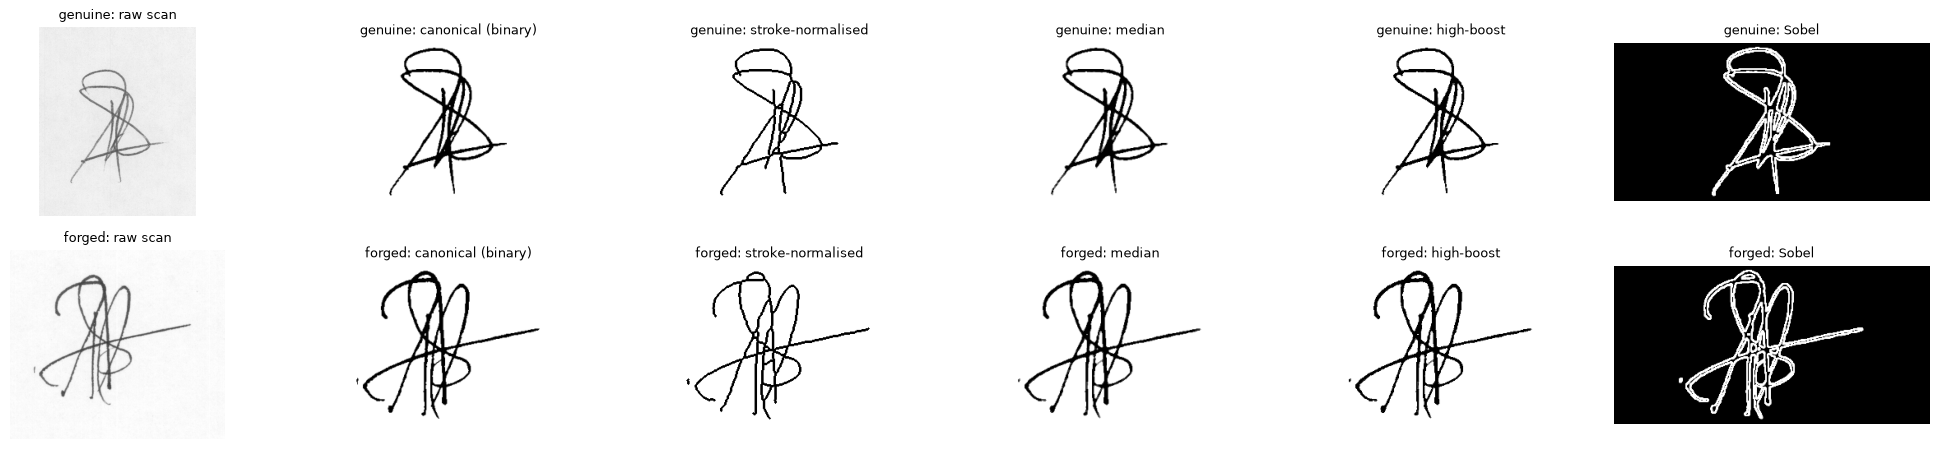

In [6]:
meta = pd.read_csv(os.path.join(DATA, "meta.csv"))
picks = [meta[(meta.writer == 27) & (meta.label == l) & (meta["index"] == 1)].index[0] for l in (0, 1)]
titles = ["raw scan", "canonical (binary)", "stroke-normalised", "median", "high-boost", "Sobel"]
fig, axes = plt.subplots(2, 6, figsize=(20, 4.6))
for r, k in enumerate(picks):
    gray = cv2.imread(os.path.join(DATA, meta.path[k]), cv2.IMREAD_GRAYSCALE)
    canon = canonical_image(gray, binarize=True)
    _, s2, s3, s4 = pipeline_stages(canon)
    for c, img in enumerate([gray, canon, normalise_strokes(canon), s2, s3, s4]):
        axes[r, c].imshow(img, cmap="gray", vmin=0, vmax=255)
        axes[r, c].set_title(f"{'genuine' if r == 0 else 'forged'}: {titles[c]}", fontsize=9)
        axes[r, c].axis("off")
plt.tight_layout()
plt.show()